# 02 · PD scorecard and validation
WoE/IV binning → feature selection → Statsmodels logit → points scaling (PDO 20, 600 points at 50:1).

In [1]:
import json, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
R = '../reports/'; F = R + 'figures/'
res = json.load(open(R + 'results.json'))

## Information Value ranking (train)
IV < 0.02 dropped; IV > 0.5 would be flagged as possible leakage.

In [2]:
pd.read_csv(R + 'iv_table.csv')

,feature,iv_fine,iv_coarse,n_bins,woe_monotonic,strength
0,annual_inc,0.0907,0.0905,14,True,weak
1,tot_hi_cred_lim,0.0794,0.0791,13,True,weak
2,bc_open_to_buy,0.0810,0.0786,10,True,weak
3,avg_cur_bal,0.0745,0.0737,10,True,weak
4,total_rev_hi_lim,0.0586,0.0577,11,True,weak
5,acc_open_past_24mths,0.0574,0.0564,8,True,weak
6,dti,0.0527,0.0524,13,True,weak
7,num_tl_op_past_12m,0.0495,0.0492,6,True,weak
8,mort_acc,0.0476,0.0474,6,True,weak
9,loan_to_income,0.0431,0.0427,9,True,weak


In [3]:
json.dumps(res['pd_scorecard']['selection'], indent=1)

'{\n "iv_below_min": [\n  "emp_length_yrs",\n  "revol_bal",\n  "purpose",\n  "revol_util",\n  "addr_state",\n  "verification_status",\n  "total_acc",\n  "loan_amnt",\n  "pub_rec",\n  "pub_rec_bankruptcies",\n  "delinq_2yrs",\n  "mths_since_last_delinq",\n  "pct_tl_nvr_dlq",\n  "open_acc"\n ],\n "iv_suspicious": [],\n "dropped_correlation": {\n  "avg_cur_bal": "|corr| 0.87 with tot_hi_cred_lim",\n  "total_rev_hi_lim": "|corr| 0.70 with bc_open_to_buy",\n  "num_tl_op_past_12m": "|corr| 0.70 with acc_open_past_24mths",\n  "bc_util": "|corr| 0.71 with bc_open_to_buy",\n  "inq_last_6mths": "|corr| 0.76 with mths_since_recent_inq",\n  "credit_hist_months": "|corr| 0.85 with mo_sin_old_rev_tl_op"\n },\n "dropped_vif": {},\n "dropped_sign_or_pvalue": {\n  "mort_acc": "p-value 0.187"\n },\n "final": [\n  "annual_inc",\n  "tot_hi_cred_lim",\n  "bc_open_to_buy",\n  "acc_open_past_24mths",\n  "dti",\n  "loan_to_income",\n  "home_ownership",\n  "mo_sin_rcnt_tl",\n  "mo_sin_old_rev_tl_op",\n  "perce

## Manual vs automatic binning (revolving utilisation)
Manual: round business cut-points. Automatic: 20 quantile bins merged until WoE is monotonic and each bin holds ≥ 5% of loans.

In [4]:
display(pd.read_csv(R + 'manual_binning_revol_util.csv')); display(pd.read_csv(R + 'auto_binning_revol_util.csv'))

,revol_util,good,bad,n,share,bad_rate,pct_good,pct_bad,woe,iv_bin
0,<= 20,17293,1857,19150,0.072816,0.096971,0.075748,0.053536,0.347054,7.708742e-03
1,"(20, 40]",45290,5948,51238,0.194827,0.116086,0.198380,0.171446,0.145913,3.929956e-03
2,"(40, 60]",66942,10142,77084,0.293104,0.131571,0.293219,0.292325,0.003055,2.731763e-06
3,"(60, 80]",62333,10257,72590,0.276016,0.141300,0.273031,0.295639,-0.079555,1.798610e-03
4,> 80,36325,6472,42797,0.162731,0.151226,0.159112,0.186549,-0.159087,4.364922e-03
5,Missing,116,17,133,0.000506,0.127820,0.000510,0.000504,0.011645,6.880263e-08


,revol_util,good,bad,n,share,bad_rate,pct_good,pct_bad,woe,iv_bin
0,<= 15.9,11898,1253,13151,0.050005,0.095278,0.052117,0.036126,0.366477,5.860297e-03
1,"(15.9, 24.1]",11885,1397,13282,0.050503,0.105180,0.052060,0.040276,0.256638,3.024193e-03
2,"(24.1, 38.7]",35002,4597,39599,0.150571,0.116089,0.153315,0.132500,0.145911,3.037116e-03
3,"(38.7, 46.1]",22717,3292,26009,0.098897,0.126572,0.099505,0.094890,0.047492,2.191910e-04
4,"(46.1, 52.9]",22994,3521,26515,0.100821,0.132793,0.100719,0.101490,-0.007628,5.882877e-06
5,"(52.9, 62.6]",33873,5290,39163,0.148913,0.135076,0.148370,0.152473,-0.027276,1.119019e-04
6,"(62.6, 73]",33908,5545,39453,0.150016,0.140547,0.148523,0.159822,-0.073317,8.283682e-04
7,"(73, 86.1]",33920,5705,39625,0.150670,0.143975,0.148576,0.164433,-0.101407,1.608021e-03
8,> 86.1,21986,4076,26062,0.099098,0.156396,0.096304,0.117485,-0.198806,4.211022e-03
9,Missing,116,17,133,0.000506,0.127820,0.000510,0.000504,0.011694,6.937913e-08


## Statsmodels coefficient table
All coefficients should be negative (higher WoE = safer = lower PD).

In [5]:
pd.read_csv(R + 'coefficients_statsmodels.csv')

,feature,coef,std_err,z,p_value,ci_low,ci_high
0,const,-1.886488,0.006004,-314.201344,0.000000e+00,-1.898256,-1.874720
1,annual_inc,-0.286727,0.026935,-10.645033,1.839190e-26,-0.339520,-0.233935
2,tot_hi_cred_lim,-0.538216,0.034189,-15.742414,7.743262e-56,-0.605225,-0.471207
3,bc_open_to_buy,-0.635811,0.029333,-21.675552,3.490303e-104,-0.693303,-0.578319
4,acc_open_past_24mths,-0.901583,0.029423,-30.642523,3.323997e-206,-0.959250,-0.843916
5,dti,-0.503539,0.028377,-17.744598,1.897533e-70,-0.559157,-0.447921
6,loan_to_income,-0.859605,0.031119,-27.623083,5.877809e-168,-0.920597,-0.798613
7,home_ownership,-0.378695,0.036869,-10.271411,9.480785e-25,-0.450957,-0.306434
8,mo_sin_rcnt_tl,-0.467885,0.036562,-12.796914,1.705967e-37,-0.539546,-0.396224
9,mo_sin_old_rev_tl_op,-0.382715,0.032366,-11.824707,2.909152e-32,-0.446151,-0.319279


## Points table and a worked example

In [6]:
pd.read_csv(R + 'scorecard_points.csv')[['feature','bin','woe','coef','points']]

,feature,bin,woe,coef,points
0,annual_inc,"<= 26,000",-0.553237,-0.286728,45
1,annual_inc,"(26,000, 36,000]",-0.395075,-0.286728,46
2,annual_inc,"(36,000, 40,000]",-0.260478,-0.286728,47
3,annual_inc,"(40,000, 46,800]",-0.166922,-0.286728,48
4,annual_inc,"(46,800, 50,000]",-0.102107,-0.286728,48
...,...,...,...,...,...
101,mths_since_recent_inq,"(4, 6]",-0.025756,-0.811348,49
102,mths_since_recent_inq,"(6, 9]",0.047979,-0.811348,50
103,mths_since_recent_inq,"(9, 11]",0.097892,-0.811348,52
104,mths_since_recent_inq,> 11,0.172571,-0.811348,53


In [7]:
w = pd.read_csv(R + 'worked_example.csv'); display(w); print('Total score:', w.points.sum(), '-> PD', res['pd_scorecard']['worked_example_pd'])

,feature,value,bin,points
0,annual_inc,65000.0,"(60,000, 65,000]",50
1,tot_hi_cred_lim,314017.0,"(306,555, 465,858]",57
2,bc_open_to_buy,57830.0,"> 22,013",62
3,acc_open_past_24mths,4.0,"(3, 4]",49
4,dti,16.06,"(15.71, 19.06]",50
5,loan_to_income,0.38,> 0.3462,40
6,home_ownership,MORTGAGE,OTHER / MORTGAGE,52
7,mo_sin_rcnt_tl,2.0,"(1, 2]",46
8,mo_sin_old_rev_tl_op,192.0,"(154, 196]",50
9,percent_bc_gt_75,7.7,<= 14.3,54


Total score: 553 -> PD 0.0925


## Validation: train vs out-of-time

In [8]:
v = res['pd_validation']; pd.DataFrame({k: {m: v[k][m] for m in ['n','bad_rate','mean_pd','auc','gini','ks','brier']} for k in ['train','oot']})

,train,oot
n,262992.000000,282615.000000
bad_rate,0.131917,0.148633
mean_pd,0.131757,0.133089
auc,0.657121,0.664838
gini,0.314242,0.329676
ks,0.224344,0.239256
brier,0.110330,0.121349


In [9]:
print('PSI (score):', round(v['psi_score'], 4), v['psi_status']); pd.read_csv(R + 'csi_features.csv')

PSI (score): 0.0013 stable


,feature,csi,status
0,mo_sin_old_rev_tl_op,0.027672,stable
1,percent_bc_gt_75,0.026277,stable
2,dti,0.023687,stable
3,acc_open_past_24mths,0.018166,stable
4,bc_open_to_buy,0.011914,stable
5,tot_hi_cred_lim,0.008198,stable
6,loan_to_income,0.004059,stable
7,mo_sin_rcnt_tl,0.003892,stable
8,home_ownership,0.003820,stable
9,mths_since_recent_inq,0.003496,stable


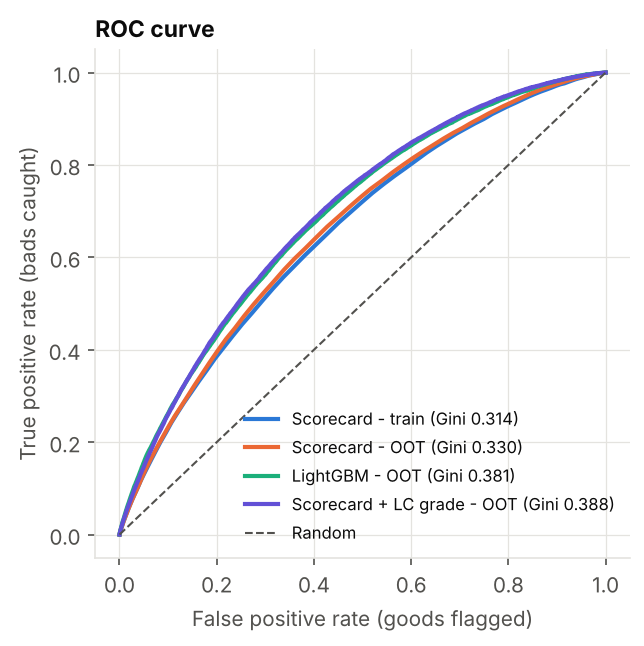

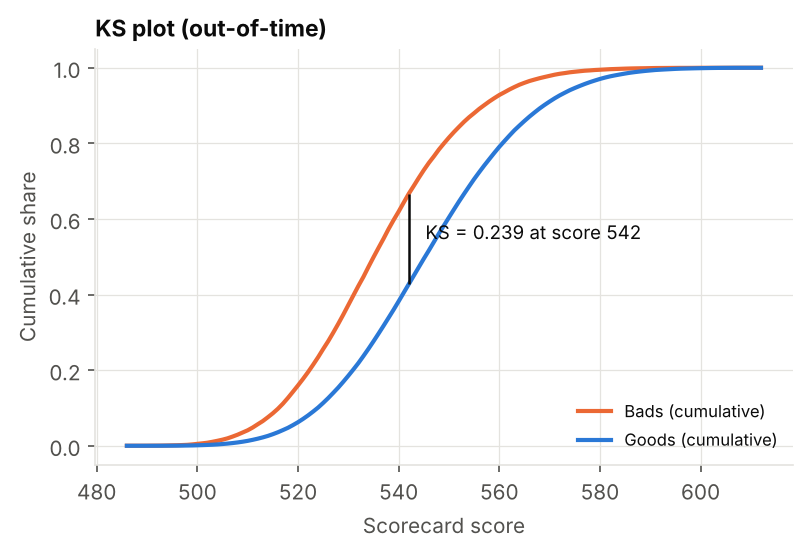

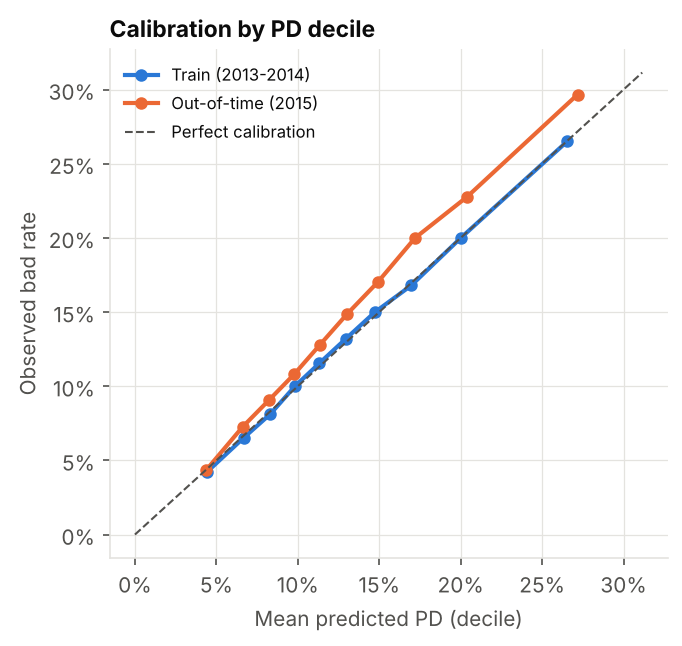

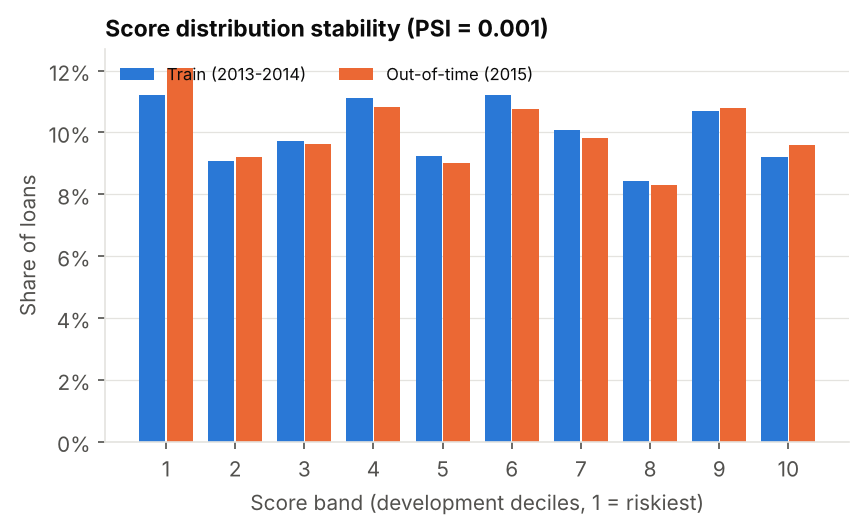

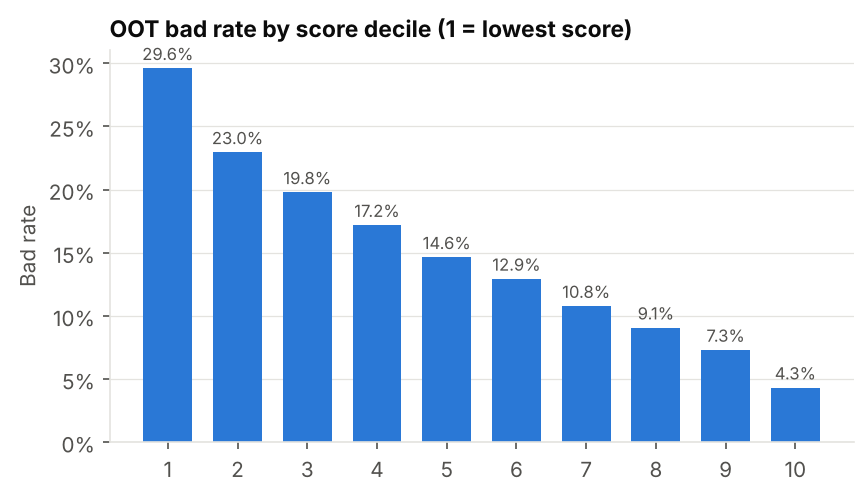

In [10]:
for f in ['roc','ks','calibration','psi','gains_oot']: display(Image(F + f + '.png'))

In [11]:
display(pd.read_csv(R + 'calibration_oot.csv')); display(pd.read_csv(R + 'gains_oot.csv'))

,band,n,bads,pd_mean,pd_min,pd_max,observed_rate,ratio_obs_pred,binom_p
0,1,28262,1233,0.043838,0.013023,0.057163,0.043627,0.995203,8.844906e-01
1,2,28261,2055,0.066213,0.057163,0.074074,0.072715,1.098197,1.485159e-05
2,3,28262,2570,0.082568,0.074074,0.089661,0.090935,1.101336,4.734240e-07
3,4,28261,3059,0.097908,0.089661,0.104847,0.108241,1.105537,8.619150e-09
4,5,28262,3614,0.113540,0.104847,0.122259,0.127875,1.126257,8.335330e-14
5,6,28261,4200,0.130203,0.122259,0.137931,0.148615,1.141411,1.755928e-19
6,7,28261,4810,0.149111,0.137931,0.159857,0.170199,1.141424,1.457297e-22
7,8,28262,5651,0.171987,0.159857,0.184522,0.199950,1.162592,2.800351e-34
8,9,28261,6431,0.203778,0.184522,0.223844,0.227557,1.116693,1.276212e-22
9,10,28262,8383,0.271743,0.223844,0.509728,0.296617,1.091536,1.209641e-20


,band,n,bads,score_min,score_max,bad_rate,cum_bad_capture,cum_pop,lift
0,1,28262,8370,486.0,523.0,0.296157,0.199257,0.100002,1.992537
1,2,28261,6488,523.0,530.0,0.229574,0.353711,0.200000,1.544569
2,3,28262,5593,530.0,535.0,0.197898,0.486859,0.300002,1.331453
3,4,28261,4859,535.0,540.0,0.171933,0.602533,0.400000,1.156760
4,5,28262,4140,540.0,544.0,0.146486,0.701090,0.500002,0.985556
5,6,28261,3656,544.0,549.0,0.129366,0.788126,0.600000,0.870367
6,7,28261,3047,549.0,554.0,0.107816,0.860663,0.699998,0.725385
7,8,28262,2564,554.0,560.0,0.090723,0.921702,0.800000,0.610378
8,9,28261,2066,560.0,568.0,0.073104,0.970885,0.899998,0.491843
9,10,28262,1223,568.0,612.0,0.043274,1.000000,1.000000,0.291144


## Benchmarks: LightGBM, and a scorecard that includes Lending Club's own grade

In [12]:
pd.DataFrame({'scorecard': v['oot'], 'lightgbm': v['lightgbm_benchmark']['oot'], 'scorecard_with_LC_grade': res['pd_with_lc_grade']['oot']}).loc[['auc','gini','ks','brier']]

,scorecard,lightgbm,scorecard_with_LC_grade
auc,0.664838,0.690439,0.694245
gini,0.329676,0.380878,0.388490
ks,0.239256,0.275311,0.283436
brier,0.121349,0.119203,0.119302
